# Drivability by Nieghborhood
### By: Sriram Schelbert, Connor Readinger, Jake Hertzler, Weston Johnson

Our goal was to determine the best neighborhood within Pittsburgh based on the driveability of the nieghborhood. In this project, our group collected data on crashes, traffic permits, road-injuries, and road work, and organized this data based on neighborhoods.

The first data set was organized by Sriram. This data included all of the crash reports within Allegheny county in the year 2025. Each report was organized via Longitude, Latitude, and many other variables. Thus it had to be separated into each respective neighborhood using a GeoJson. After separating the file into neighborhoods, the data was then organized to show the number of crashes and the severity by including the number of crashes with injuries or fatalities.

In [2]:
import json
import pandas as pd
import geopandas as gpd
from shapely import wkb

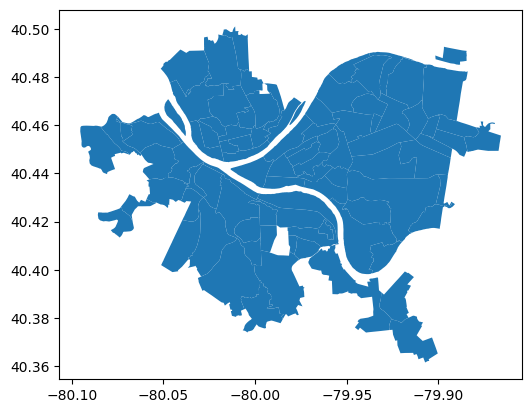

In [6]:

# Load the datastore export
with open("geodata.json", "r", encoding="utf-8") as f:
    data = json.load(f)

columns = [fld["id"] for fld in data["fields"]]
records = pd.DataFrame(data["records"], columns=columns)

# Strip the leading "\x" and decode the hex WKB into shapely geometries
def parse_wkb(s):
    if s is None:
        return None
    if s.startswith("\\x"):
        s = s[2:]
    return wkb.loads(s, hex=True)

records["geometry"] = records["dataspatial_wkb"].apply(parse_wkb)

neighborhoods = gpd.GeoDataFrame(
    records.drop(columns=["dataspatial_wkb"]),
    geometry="geometry",
    crs="EPSG:4326",   # the coordinates (~ -79.9, 40.4) are already lat/lon
)

# Crashes
crash = pd.read_csv("crash_allegheny_2025.csv")
crash = crash.dropna(subset=["DEC_LONGITUDE", "DEC_LATITUDE"])

crashes_gdf = gpd.GeoDataFrame(
    crash,
    geometry=gpd.points_from_xy(crash["DEC_LONGITUDE"], crash["DEC_LATITUDE"]),
    crs="EPSG:4326",
)

# Spatial join with geojson and latitude and longitude from csv
joined = gpd.sjoin(
    crashes_gdf,
    neighborhoods[["hood", "geometry"]],
    how="left",
    predicate="within",
)

joined = joined.rename(columns={"hood": "neighborhood"}).drop(columns=["geometry", "index_right"])

# print(len(joined) == len(crashes_gdf))      # Should be True if no duplicate matches
# print(joined["neighborhood"].isna().sum())  # Crashes outside the city polygons
joined.to_csv("crashes_with_neighborhoods.csv", index=False)

# print(neighborhoods.shape)
# print(neighborhoods.geometry.isna().sum())
neighborhoods.plot()

# Making a new column to describe the severity of the crashes
# Severity category for each crash (later lines overwrite earlier ones)
joined["severity"] = "No injury/fatality"
joined.loc[joined["INJURY_COUNT"] > 0, "severity"] = "Injury"
joined.loc[joined["FATAL_COUNT"] > 0, "severity"] = "Fatal"   # use your actual column name

# Rows = neighborhoods, columns = severity, values = number of crashes
stacked = pd.crosstab(joined["neighborhood"], joined["severity"])

# Fix stacking order, then sort neighborhoods by total crashes
stacked = stacked[["Fatal", "Injury", "No injury/fatality"]]
stacked = stacked.loc[stacked.sum(axis=1).sort_values(ascending=False).index]


### Neighborhoods
This is a map of the Greater Pittsburgh Area separated by neighborhoods.

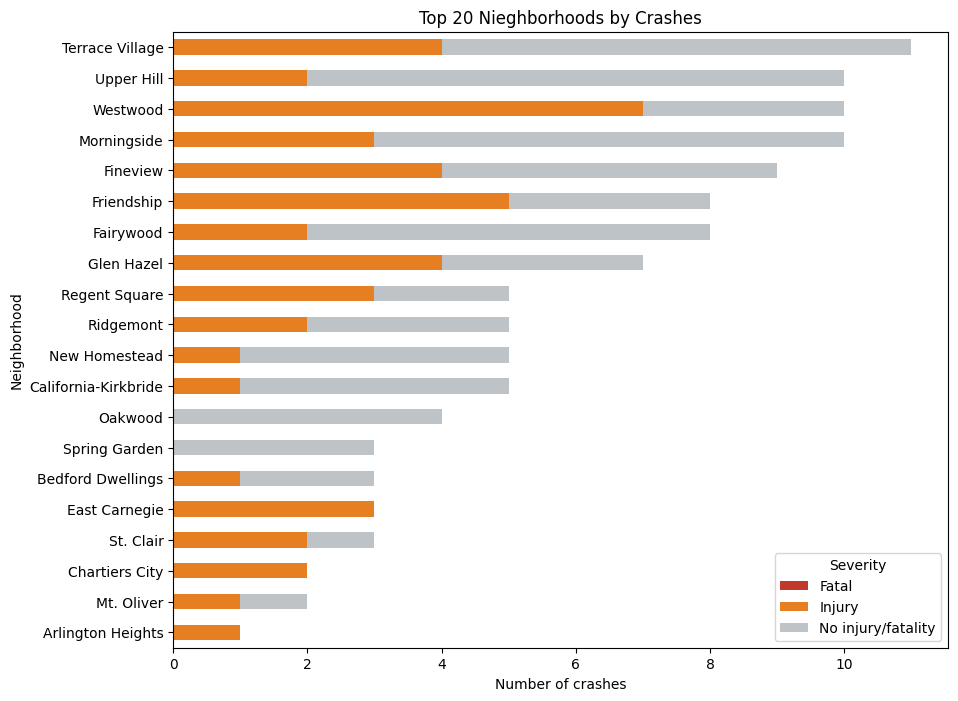

In [5]:
ax = stacked.tail(20).plot.barh(
    stacked=True,
    figsize=(10, 8),
    color=["#c0392b", "#e67e22", "#bdc3c7"],   # fatal, injury, none
    title="Top 20 Nieghborhoods by Crashes",
    xlabel="Number of crashes",
    ylabel="Neighborhood",
)
ax.invert_yaxis()   # largest at the top
ax.legend(title="Severity")

### Top 20 Neighborhoods
This is a stacked bar graph displaying the top 20 neigborhoods organized by the number of crashes and separated by the severity of said crashes.

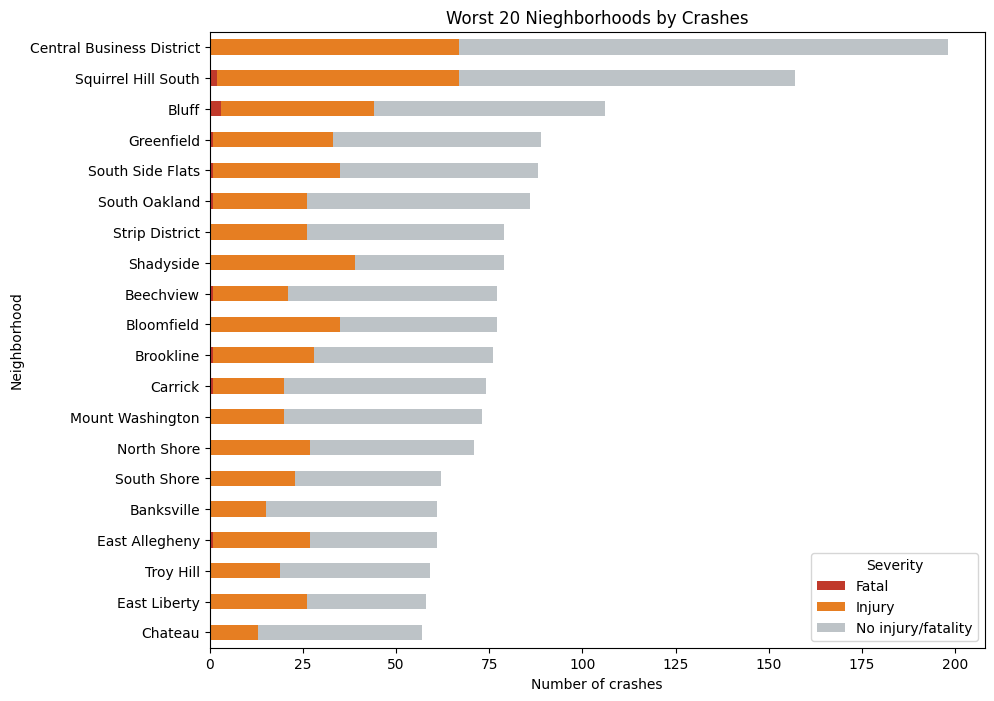

In [4]:
ax = stacked.head(20).plot.barh(
    stacked=True,
    figsize=(10, 8),
    color=["#c0392b", "#e67e22", "#bdc3c7"],   # fatal, injury, none
    title="Worst 20 Nieghborhoods by Crashes",
    xlabel="Number of crashes",
    ylabel="Neighborhood",
)
ax.invert_yaxis()   # largest at the top
ax.legend(title="Severity")

### Worst 20 Neighborhoods
This is a stacked bar graph displaying the worst 20 neigborhoods organized by the number of crashes and separated by the severity of said crashes.

### Conclusion
Overall, the best neighborhood to live in based on the number and severity of crashes that occured within each respective neighbood is either Arlington Heights or Spring Garden as Arlington has the least total number of crashes while Spring Garden has the lowest severity of crashes while still keeping a low total of crashes within the respective neighborhoods. In comparison, the worst neighborhood by the crash count is the Central Business District, while its contender for severity is either Squirrel Hill South or Bluff due to the fatalities that occured from the crashes, making them the neighborhoods with the most severe crashes.